# Ensemble Model Figures and Analysis

Calibration comparison, SHAP analysis, decision curves, and overfitting assessment.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

DATA_PATH = PROJECT_ROOT / "data" / "clean" / "processed_dataset.csv"
PANELS_PATH = PROJECT_ROOT / "data" / "clean" / "feature_panels.json"
REPORTS = PROJECT_ROOT / "reports"

## Data and Model Loading

In [2]:
from models.baselines.baseline_utils import load_dataset, load_panels, temporal_split

df = load_dataset(DATA_PATH)
panels = load_panels(PANELS_PATH)

# Load Panel C data (Combined) for figures
split_c = temporal_split(df, panels["PanelC_Combined"])
X_test_df = split_c.x_test  # Keep as DataFrame for feature names
X_test = X_test_df.to_numpy()
y_test = split_c.y_test.to_numpy()
feature_names = list(X_test_df.columns)

# Load best models
baseline_model = joblib.load(REPORTS / "baselines" / "models" / "PanelC_Combined_svm_linear_tuned.joblib")
ensemble_model = joblib.load(REPORTS / "ensembles" / "models" / "PanelC_Combined_stacking_tuned.joblib")

print(f"Test set: {len(y_test)} samples, {y_test.mean():.1%} positive")
print(f"Features: {feature_names}")

Test set: 5040 samples, 60.9% positive
Features: ['ACR_mg_g_log', 'BMXBMI', 'LBXHGB', 'LBXPLTSI', 'LBXRDW', 'LBXSAL', 'LBXSBU', 'LBXSCR_log', 'LBXSUA', 'LBXWBCSI', 'RIDAGEYR', 'URXUCR', 'URXUMA', 'eGFR', 'race_mexican_american', 'race_non_hispanic_asian', 'race_non_hispanic_black', 'race_non_hispanic_white', 'race_other_hispanic', 'race_other_race', 'sex_female']


## Calibration Curves (Ensemble vs Baseline)

/Users/khaledmazahreh/Documents/hypertension_trial/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


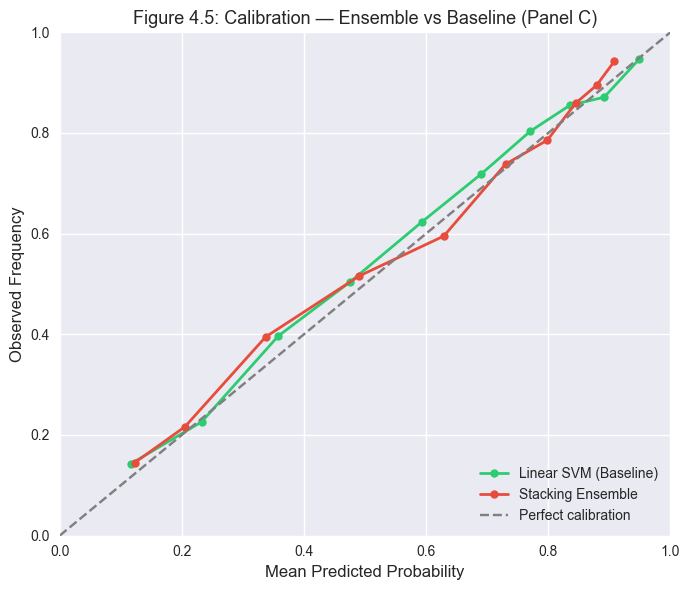

In [3]:
from sklearn.calibration import calibration_curve

# Get predictions
y_prob_baseline = baseline_model.predict_proba(X_test)[:, 1]
y_prob_ensemble = ensemble_model.predict_proba(X_test)[:, 1]

# Calibration curves
fig, ax = plt.subplots(figsize=(7, 6))

for name, y_prob, color in [
    ("Linear SVM (Baseline)", y_prob_baseline, "#2ecc71"),
    ("Stacking Ensemble", y_prob_ensemble, "#e74c3c"),
]:
    frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=name, color=color, linewidth=2, markersize=6)

ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean Predicted Probability", fontsize=12)
ax.set_ylabel("Observed Frequency", fontsize=12)
ax.set_title("Figure 4.5: Calibration — Ensemble vs Baseline (Panel C)", fontsize=13)
ax.legend(loc="lower right")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## SHAP Beeswarm Plot

In [4]:
import shap

# SHAP on Panel C XGBoost
xgb_model = joblib.load(REPORTS / "ensembles" / "models" / "PanelC_Combined_xgboost_tuned.joblib")
X_shap = X_test_df

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_shap)

print(f"SHAP computed for {len(X_shap)} samples, {len(feature_names)} features")

SHAP computed for 5040 samples, 21 features


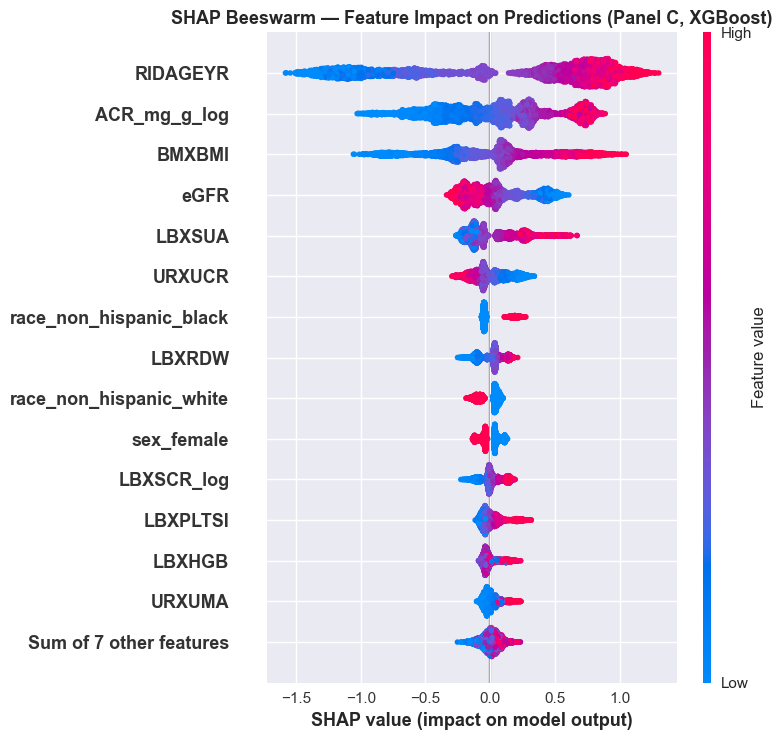

In [5]:
# beeswarm plot
fig, ax = plt.subplots(figsize=(8, 7.5))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP Beeswarm — Feature Impact on Predictions (Panel C, XGBoost)", fontsize=13, fontweight='bold')
ax = plt.gca()
ax.set_xlabel(ax.get_xlabel(), fontweight='bold')
ax.set_ylabel(ax.get_ylabel(), fontweight='bold')
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
plt.tight_layout()
plt.show()

## Decision Curve Analysis

In [6]:
def decision_curve(y_true, y_prob, thresholds):
    """Net benefit at each threshold."""
    net_benefits = []
    n = len(y_true)
    for thresh in thresholds:
        y_pred = (y_prob >= thresh).astype(int)
        tp = ((y_pred == 1) & (y_true == 1)).sum()
        fp = ((y_pred == 1) & (y_true == 0)).sum()
        nb = (tp / n) - (fp / n) * (thresh / (1 - thresh)) if thresh < 1 else 0
        net_benefits.append(nb)
    return np.array(net_benefits)

thresholds = np.linspace(0.01, 0.99, 100)

nb_baseline = decision_curve(y_test, y_prob_baseline, thresholds)
nb_ensemble = decision_curve(y_test, y_prob_ensemble, thresholds)
nb_all = decision_curve(y_test, np.ones_like(y_test), thresholds)
nb_none = np.zeros_like(thresholds)

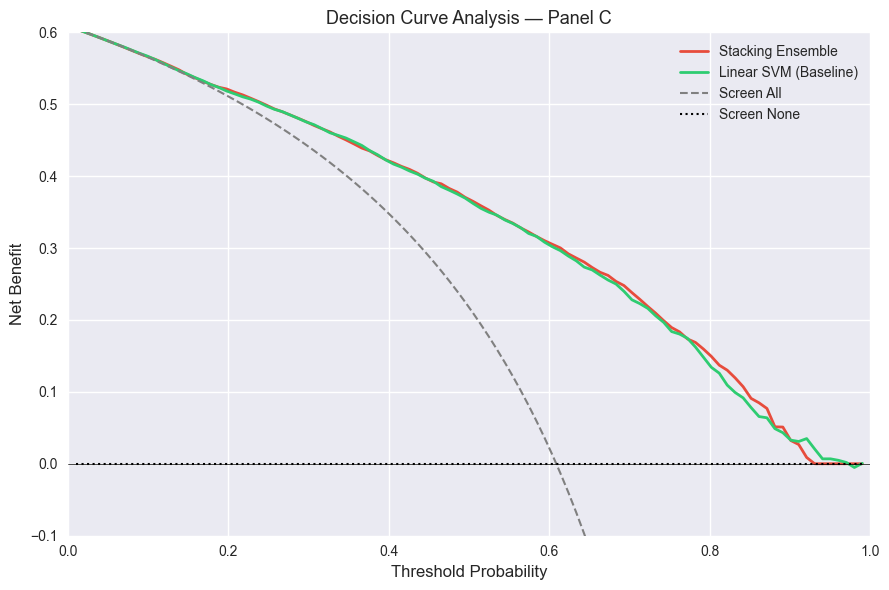

In [7]:
# Plot decision curves
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(thresholds, nb_ensemble, label="Stacking Ensemble", color="#e74c3c", linewidth=2)
ax.plot(thresholds, nb_baseline, label="Linear SVM (Baseline)", color="#2ecc71", linewidth=2)
ax.plot(thresholds, nb_all, label="Screen All", color="gray", linestyle="--", linewidth=1.5)
ax.plot(thresholds, nb_none, label="Screen None", color="black", linestyle=":", linewidth=1.5)

ax.set_xlabel("Threshold Probability", fontsize=12)
ax.set_ylabel("Net Benefit", fontsize=12)
ax.set_title("Decision Curve Analysis — Panel C", fontsize=13)
ax.legend(loc="upper right")
ax.set_xlim(0, 1)
ax.set_ylim(-0.1, 0.6)
ax.axhline(y=0, color="black", linewidth=0.5)

plt.tight_layout()
plt.show()

## SHAP Feature Importance by Panel

Mean |SHAP| values averaged across XGBoost, LightGBM, and Random Forest.

In [8]:
# load per-model SHAP CSVs
SHAP_DIR = REPORTS / "ensembles" / "shap"

panels_list = ["PanelA_RenalDemo", "PanelB_CBC", "PanelC_Combined"]
models_list = ["xgboost", "lightgbm", "random_forest"]

shap_dfs = []
for panel in panels_list:
    for model in models_list:
        csv_path = SHAP_DIR / f"shap_{panel}_{model}.csv"
        if csv_path.exists():
            shap_dfs.append(pd.read_csv(csv_path))

shap_all = pd.concat(shap_dfs, ignore_index=True)
print(f"Loaded {len(shap_dfs)} SHAP files, {len(shap_all)} rows")

Loaded 9 SHAP files, 153 rows


In [9]:
# ensemble-averaged SHAP per panel (top 10)
shap_avg = (
    shap_all.groupby(["panel", "feature"])["mean_abs_shap"]
    .mean()
    .reset_index()
)
shap_avg["rank"] = shap_avg.groupby("panel")["mean_abs_shap"].rank(ascending=False).astype(int)

def get_top10(panel_name):
    subset = shap_avg[shap_avg["panel"] == panel_name].nsmallest(10, "rank")
    return subset[["rank", "feature", "mean_abs_shap"]].sort_values("rank")

for label, key in [("Panel A (Renal)", "PanelA_RenalDemo"), 
                    ("Panel B (CBC)", "PanelB_CBC"), 
                    ("Panel C (Combined)", "PanelC_Combined")]:
    print(f"\n{label}")
    display(get_top10(key).round(2))


Panel A (Renal)


,rank,feature,mean_abs_shap
6,1,RIDAGEYR,0.54
1,2,BMXBMI,0.26
0,3,ACR_mg_g_log,0.25
9,4,eGFR,0.13
5,5,LBXSUA,0.13
7,6,URXUCR,0.10
12,7,race_non_hispanic_black,0.07
16,8,sex_female,0.06
4,9,LBXSCR_log,0.06
13,10,race_non_hispanic_white,0.05



Panel B (CBC)


,rank,feature,mean_abs_shap
22,1,RIDAGEYR,0.66
17,2,BMXBMI,0.27
29,3,sex_female,0.08
20,4,LBXRDW,0.08
25,5,race_non_hispanic_black,0.07
21,6,LBXWBCSI,0.06
18,7,LBXHGB,0.05
19,8,LBXPLTSI,0.04
26,9,race_non_hispanic_white,0.04
23,10,race_mexican_american,0.03



Panel C (Combined)


,rank,feature,mean_abs_shap
40,1,RIDAGEYR,0.51
30,2,ACR_mg_g_log,0.24
31,3,BMXBMI,0.24
43,4,eGFR,0.14
38,5,LBXSUA,0.12
41,6,URXUCR,0.08
46,7,race_non_hispanic_black,0.05
50,8,sex_female,0.05
34,9,LBXRDW,0.05
37,10,LBXSCR_log,0.04


## Combined SHAP Table (Table 4.5)

In [10]:
# feature name mapping
name_map = {
    "RIDAGEYR": "Age", "BMXBMI": "BMI", "ACR_mg_g_log": "ACR (log)",
    "LBXSUA": "Uric Acid", "eGFR": "eGFR", "URXUCR": "Urinary Creatinine",
    "race_non_hispanic_black": "Race (Black)", "LBXSCR_log": "Serum Creatinine",
    "sex_female": "Sex (Female)", "race_non_hispanic_white": "Race (White)",
    "LBXRDW": "RDW", "LBXWBCSI": "WBC", "LBXHGB": "Haemoglobin",
    "LBXPLTSI": "Platelet Count", "race_mexican_american": "Race (Mexican)",
    "LBXSAL": "Serum Albumin", "LBXSBU": "BUN", "URXUMA": "Urinary Albumin",
    "race_non_hispanic_asian": "Race (Asian)", "race_other_hispanic": "Race (Other Hisp)",
    "race_other_race": "Race (Other)"
}

shap_pivot = shap_avg.pivot(index="feature", columns="panel", values="mean_abs_shap")
shap_pivot["Feature"] = shap_pivot.index.map(lambda x: name_map.get(x, x))
shap_pivot = shap_pivot.rename(columns={
    "PanelA_RenalDemo": "Panel A", "PanelB_CBC": "Panel B", "PanelC_Combined": "Panel C"
})

shap_pivot["max_shap"] = shap_pivot[["Panel A", "Panel B", "Panel C"]].max(axis=1)
shap_pivot = shap_pivot.sort_values("max_shap", ascending=False)

table_4_5 = shap_pivot.head(12)[["Feature", "Panel A", "Panel B", "Panel C"]].copy()
table_4_5 = table_4_5.reset_index(drop=True)
table_4_5.index = table_4_5.index + 1
table_4_5.index.name = "Rank"

for col in ["Panel A", "Panel B", "Panel C"]:
    table_4_5[col] = table_4_5[col].apply(lambda x: f"{x:.2f}" if pd.notna(x) else "—")

print("Table 4.5: Global Feature Importance (Mean |SHAP|) Across Panels")
print("Ensemble-averaged across XGBoost, LightGBM, and Random Forest.\n")
display(table_4_5)

Table 4.5: Global Feature Importance (Mean |SHAP|) Across Panels
Ensemble-averaged across XGBoost, LightGBM, and Random Forest.



panel,Feature,Panel A,Panel B,Panel C
Rank,,,,
1,Age,0.54,0.66,0.51
2,BMI,0.26,0.27,0.24
3,ACR (log),0.25,—,0.24
4,eGFR,0.13,—,0.14
5,Uric Acid,0.13,—,0.12
6,Urinary Creatinine,0.10,—,0.08
7,Sex (Female),0.06,0.08,0.05
8,RDW,—,0.08,0.05
9,Race (Black),0.07,0.07,0.05


In [11]:
# per-model SHAP tables (for appendix)
for panel in panels_list:
    panel_data = shap_all[shap_all["panel"] == panel].copy()
    panel_pivot = panel_data.pivot(index="feature", columns="model", values="mean_abs_shap")
    panel_pivot["Feature"] = panel_pivot.index.map(lambda x: name_map.get(x, x))
    panel_pivot = panel_pivot.rename(columns={
        "xgboost": "XGBoost", "lightgbm": "LightGBM", "random_forest": "Random Forest"
    })
    panel_pivot = panel_pivot.sort_values("XGBoost", ascending=False)
    
    appendix_table = panel_pivot[["Feature", "XGBoost", "LightGBM", "Random Forest"]].copy()
    appendix_table = appendix_table.reset_index(drop=True)
    appendix_table.index = appendix_table.index + 1
    appendix_table.index.name = "Rank"
    for col in ["XGBoost", "LightGBM", "Random Forest"]:
        appendix_table[col] = appendix_table[col].round(2)
    
    print(f"\nAppendix: {panel} (Per-Model SHAP)")
    display(appendix_table.head(10))


Appendix: PanelA_RenalDemo (Per-Model SHAP)


model,Feature,XGBoost,LightGBM,Random Forest
Rank,,,,
1,Age,0.74,0.74,0.12
2,BMI,0.37,0.37,0.05
3,ACR (log),0.36,0.33,0.06
4,Uric Acid,0.19,0.19,0.03
5,eGFR,0.17,0.18,0.05
6,Urinary Creatinine,0.14,0.14,0.02
7,Race (Black),0.10,0.11,0.01
8,Serum Creatinine,0.08,0.08,0.01
9,Sex (Female),0.08,0.09,0.01



Appendix: PanelB_CBC (Per-Model SHAP)


model,Feature,XGBoost,LightGBM,Random Forest
Rank,,,,
1,Age,0.92,0.89,0.17
2,BMI,0.39,0.36,0.06
3,Sex (Female),0.11,0.11,0.02
4,RDW,0.11,0.10,0.03
5,Race (Black),0.10,0.08,0.01
6,WBC,0.08,0.07,0.02
7,Haemoglobin,0.08,0.07,0.01
8,Platelet Count,0.07,0.05,0.01
9,Race (White),0.06,0.05,0.00



Appendix: PanelC_Combined (Per-Model SHAP)


model,Feature,XGBoost,LightGBM,Random Forest
Rank,,,,
1,Age,0.72,0.70,0.12
2,ACR (log),0.35,0.32,0.05
3,BMI,0.35,0.33,0.04
4,eGFR,0.18,0.20,0.04
5,Uric Acid,0.18,0.15,0.02
6,Urinary Creatinine,0.12,0.10,0.01
7,Race (Black),0.08,0.08,0.00
8,RDW,0.08,0.05,0.02
9,Serum Creatinine,0.07,0.05,0.01


## Overfitting Assessment

Train-test AUC gaps and learning curves for Panel A.

In [12]:
# train vs test AUC for all tuned models
from sklearn.metrics import roc_auc_score
import json as _json

with open(PANELS_PATH) as f:
    panels_cfg = _json.load(f)

df_full = pd.read_csv(DATA_PATH)
train_df = df_full[df_full["cycle"] == "2015_2016"]
test_df  = df_full[df_full["cycle"] == "2017_2018"]
y_train  = train_df["HTN_13080"]
y_test_all = test_df["HTN_13080"]

BASE_DIR = REPORTS / "baselines" / "models"
ENS_DIR  = REPORTS / "ensembles" / "models"

baseline_names = ["logreg", "decision_tree", "knn", "svm_linear"]
ensemble_names = ["random_forest", "xgboost", "lightgbm", "voting", "stacking"]
panel_keys     = ["PanelA_RenalDemo", "PanelB_CBC", "PanelC_Combined"]

rows = []
for panel in panel_keys:
    feats = panels_cfg[panel]
    X_tr = train_df[feats]
    X_te = test_df[feats]

    for mname in baseline_names:
        model = joblib.load(BASE_DIR / f"{panel}_{mname}_tuned.joblib")
        tr_auc = roc_auc_score(y_train, model.predict_proba(X_tr)[:, 1])
        te_auc = roc_auc_score(y_test_all, model.predict_proba(X_te)[:, 1])
        rows.append({"Panel": panel, "Model": mname, "Type": "Baseline",
                      "Train AUC": tr_auc, "Test AUC": te_auc, "Gap": tr_auc - te_auc})

    for mname in ensemble_names:
        model = joblib.load(ENS_DIR / f"{panel}_{mname}_tuned.joblib")
        tr_auc = roc_auc_score(y_train, model.predict_proba(X_tr)[:, 1])
        te_auc = roc_auc_score(y_test_all, model.predict_proba(X_te)[:, 1])
        rows.append({"Panel": panel, "Model": mname, "Type": "Ensemble",
                      "Train AUC": tr_auc, "Test AUC": te_auc, "Gap": tr_auc - te_auc})

gap_df = pd.DataFrame(rows).round(4)
print("Train vs Test AUC (all tuned models)\n")
print(gap_df.to_string(index=False))

/Users/khaledmazahreh/Documents/hypertension_trial/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/Users/khaledmazahreh/Documents/hypertension_trial/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/Users/khaledmazahreh/Documents/hypertension_trial/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/khaledmazahreh/Documents/hypertension_trial/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/khaledmazahreh/Documents/hypertension_trial/.venv/lib/python3.14/site-package

Train vs Test AUC (all tuned models)

           Panel         Model     Type  Train AUC  Test AUC    Gap
PanelA_RenalDemo        logreg Baseline     0.8229    0.8183 0.0046
PanelA_RenalDemo decision_tree Baseline     0.8228    0.7837 0.0391
PanelA_RenalDemo           knn Baseline     0.8309    0.7970 0.0339
PanelA_RenalDemo    svm_linear Baseline     0.8220    0.8185 0.0035
PanelA_RenalDemo random_forest Ensemble     0.8852    0.8116 0.0736
PanelA_RenalDemo       xgboost Ensemble     0.8485    0.8154 0.0331
PanelA_RenalDemo      lightgbm Ensemble     0.8537    0.8154 0.0383
PanelA_RenalDemo        voting Ensemble     0.8501    0.8208 0.0293
PanelA_RenalDemo      stacking Ensemble     0.8428    0.8214 0.0214
      PanelB_CBC        logreg Baseline     0.8052    0.8046 0.0006
      PanelB_CBC decision_tree Baseline     0.8044    0.7799 0.0245
      PanelB_CBC           knn Baseline     0.8216    0.7876 0.0340
      PanelB_CBC    svm_linear Baseline     0.8047    0.8038 0.0010
      Pane

Logistic Regression: Train=0.8231, CV Val=0.8208, Gap=+0.0023
XGBoost: Train=0.8829, CV Val=0.8179, Gap=+0.0650
Stacking: Train=0.8435, CV Val=0.8228, Gap=+0.0207


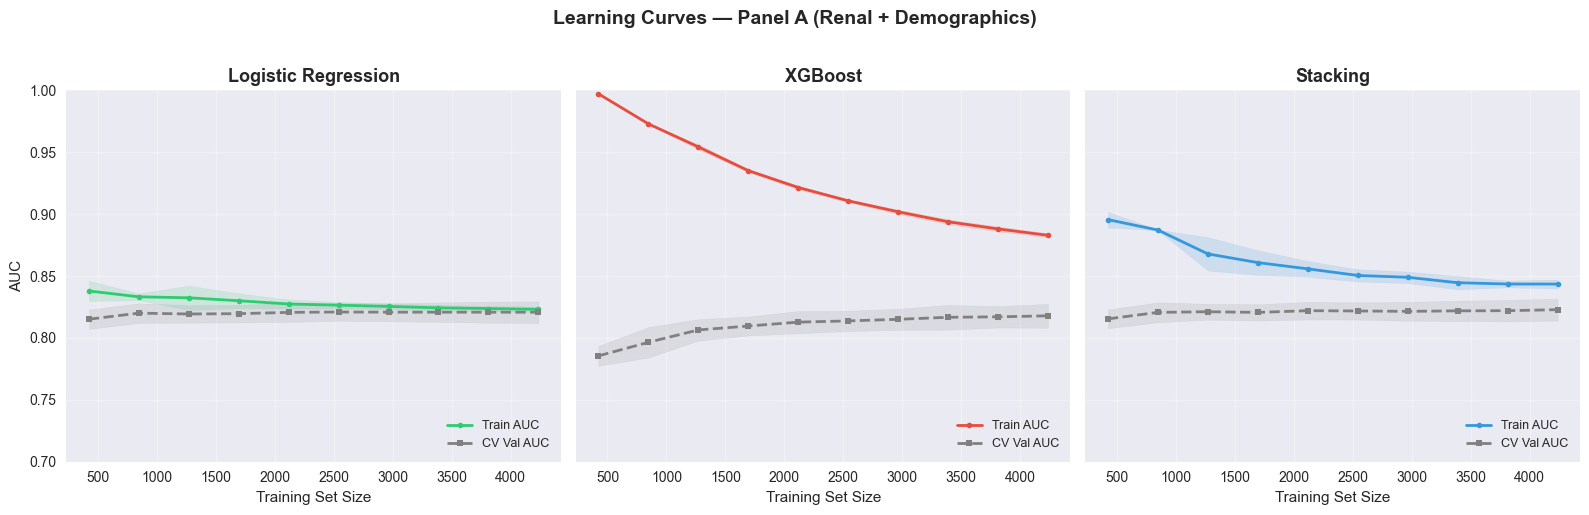

In [13]:
# learning curves: LR, XGBoost, Stacking (Panel A)
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier, RandomForestClassifier

feats_a = panels_cfg["PanelA_RenalDemo"]
X_tr_a = train_df[feats_a].to_numpy()
y_tr_a = y_train.to_numpy()

models_lc = {
    "Logistic Regression": LogisticRegression(C=0.1, max_iter=1000, solver="lbfgs"),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
        use_label_encoder=False, eval_metric="logloss", random_state=42, verbosity=0),
    "Stacking": StackingClassifier(
        estimators=[
            ("lr", LogisticRegression(C=0.1, max_iter=1000, solver="lbfgs")),
            ("rf", RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)),
            ("xgb", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                   use_label_encoder=False, eval_metric="logloss",
                                   random_state=42, verbosity=0)),
        ],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5, passthrough=False),
}

train_sizes_frac = np.linspace(0.1, 1.0, 10)
colors = {"Logistic Regression": "#2ecc71", "XGBoost": "#e74c3c", "Stacking": "#3498db"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (name, estimator) in zip(axes, models_lc.items()):
    train_sizes_abs, train_scores, val_scores = learning_curve(
        estimator, X_tr_a, y_tr_a,
        train_sizes=train_sizes_frac, cv=5, scoring="roc_auc",
        n_jobs=-1, random_state=42)

    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    c = colors[name]
    ax.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.15, color=c)
    ax.fill_between(train_sizes_abs, val_mean - val_std, val_mean + val_std, alpha=0.15, color="gray")
    ax.plot(train_sizes_abs, train_mean, "o-", color=c, label="Train AUC", linewidth=2, markersize=4)
    ax.plot(train_sizes_abs, val_mean, "s--", color="gray", label="CV Val AUC", linewidth=2, markersize=4)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Training Set Size", fontsize=11)
    if ax == axes[0]:
        ax.set_ylabel("AUC", fontsize=11)
    ax.legend(loc="lower right", fontsize=9)
    ax.set_ylim(0.70, 1.0)
    ax.grid(True, alpha=0.3)

    gap = train_mean[-1] - val_mean[-1]
    print(f"{name}: Train={train_mean[-1]:.4f}, CV Val={val_mean[-1]:.4f}, Gap={gap:+.4f}")

fig.suptitle("Learning Curves — Panel A (Renal + Demographics)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# Panel A summary table
panel_a_gap = gap_df[gap_df["Panel"] == "PanelA_RenalDemo"][["Model", "Type", "Train AUC", "Test AUC", "Gap"]].copy()
panel_a_gap = panel_a_gap.sort_values("Gap", ascending=False)
print("Panel A: Train vs Test AUC\n")
print(panel_a_gap.to_string(index=False))

Panel A: Train vs Test AUC

        Model     Type  Train AUC  Test AUC    Gap
random_forest Ensemble     0.8852    0.8116 0.0736
decision_tree Baseline     0.8228    0.7837 0.0391
     lightgbm Ensemble     0.8537    0.8154 0.0383
          knn Baseline     0.8309    0.7970 0.0339
      xgboost Ensemble     0.8485    0.8154 0.0331
       voting Ensemble     0.8501    0.8208 0.0293
     stacking Ensemble     0.8428    0.8214 0.0214
       logreg Baseline     0.8229    0.8183 0.0046
   svm_linear Baseline     0.8220    0.8185 0.0035
